In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

In [2]:
plots = Path("plots") / "compression"

In [3]:
compression_ratios_single = pd.read_csv("compression-ratio-single.csv")

In [4]:
compression_ratios_pressure = pd.read_csv("compression-ratio-pressure.csv")

In [5]:
import matplotlib
from matplotlib import pyplot as plt
from matplotlib import ticker as mtick

In [6]:
tab20c = matplotlib.colormaps["tab20c"].colors

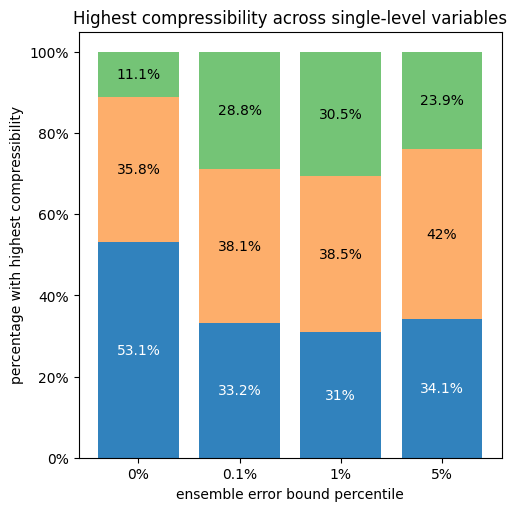

In [7]:
fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")

variables = list(compression_ratios_single["name"].unique())
percentiles = list(compression_ratios_single["percentile"].unique())
kinds = list(compression_ratios_single["kind"].unique())
colours = [tab20c[0], tab20c[4 + 2], tab20c[8 + 1]]

for i, percentile in enumerate(percentiles):
    base = 0

    for j, (kind, c) in enumerate(zip(kinds, colours)):
        count = 0
        for v in variables:
            count += (
                np.argmax(
                    [
                        compression_ratios_single[
                            (compression_ratios_single["name"] == v)
                            & (compression_ratios_single["level"] == "single")
                            & (compression_ratios_single["percentile"] == percentile)
                            & (compression_ratios_single["kind"] == k)
                        ]["cr"].iloc[0]
                        for k in kinds
                    ]
                )
                == j
            )

        ax.bar(
            i,
            count / len(variables),
            bottom=base / len(variables),
            color=c,
        )

        ax.text(
            i,
            (count + base * 2) / (2 * len(variables)),
            f"{np.format_float_positional(count / len(variables) * 100, trim='-', precision=1)}%",
            va="center",
            ha="center",
            color=["white", "black", "black"][j],
        )

        base += count

ax.set_title("Highest compressibility across single-level variables")
ax.set_xticks(range(len(percentiles)))
ax.set_xticklabels(
    [
        f"{np.format_float_positional(p * 100, trim='-', precision=1)}%"
        for p in percentiles
    ]
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))

ax.set_xlabel("ensemble error bound percentile")
ax.set_ylabel("percentage with highest compressibility")

plt.show()
fig.savefig(plots / "single.pdf")

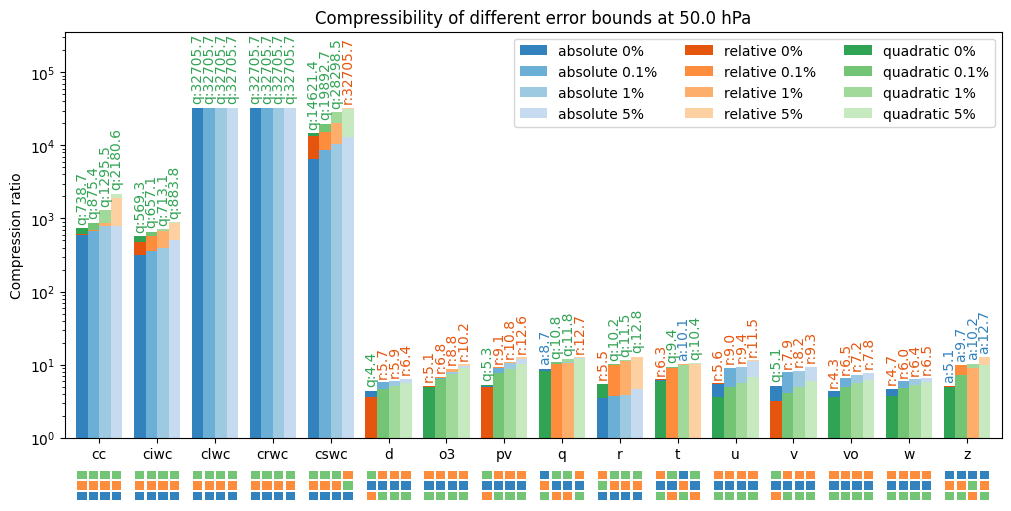

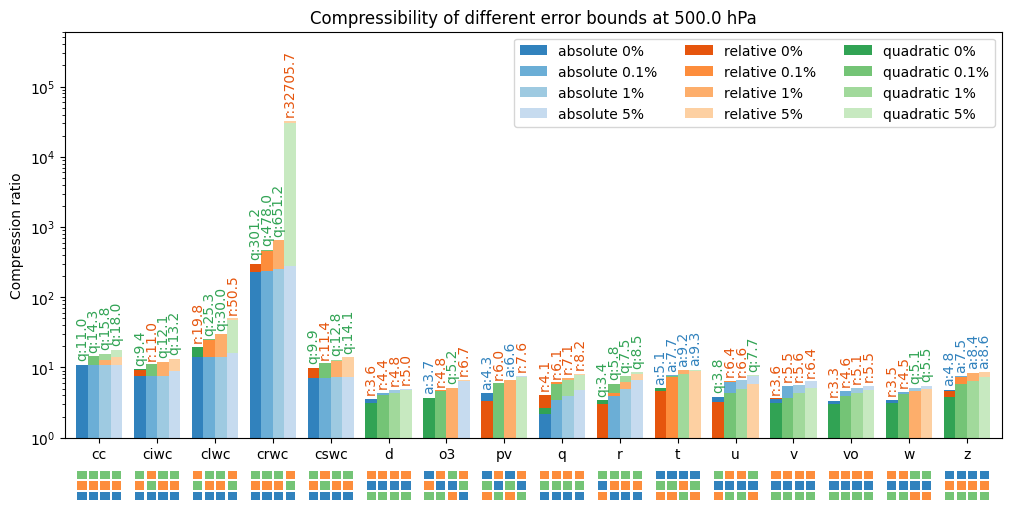

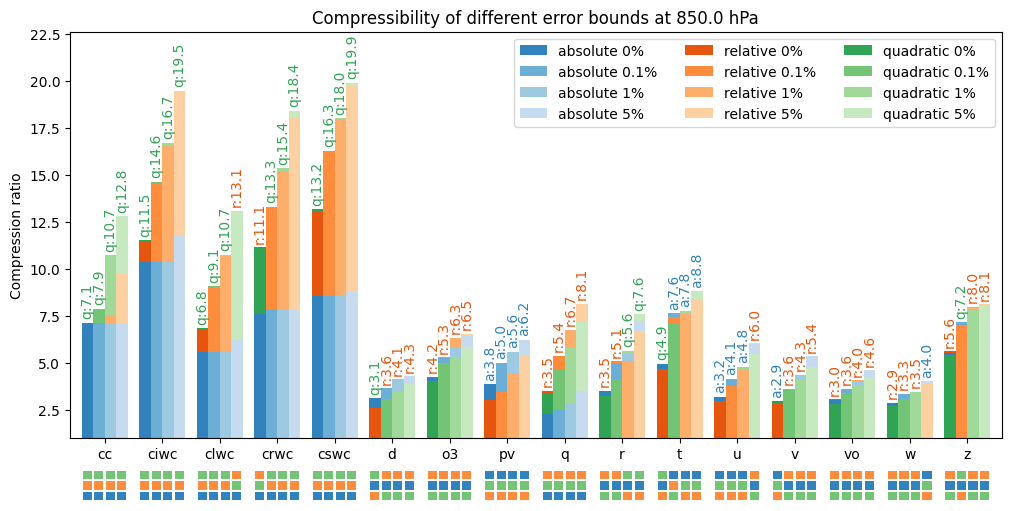

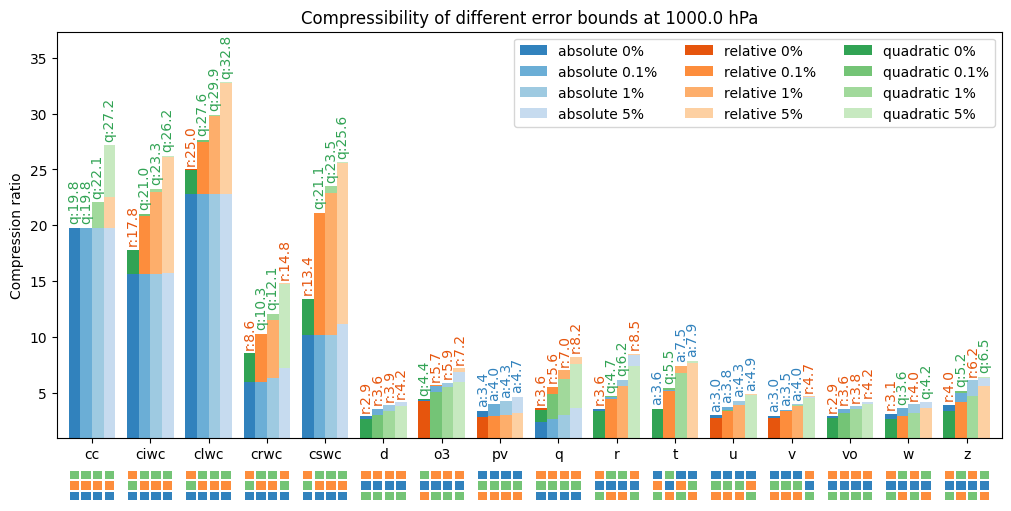

In [8]:
variables = list(compression_ratios_pressure["name"].unique())
levels = list(compression_ratios_pressure["level"].unique())
percentiles = list(compression_ratios_pressure["percentile"].unique())

x = np.arange(len(variables))
width = 0.2

for level in levels:
    fig, (ax, axt) = plt.subplots(
        2,
        1,
        figsize=(10, 5),
        layout="constrained",
        height_ratios=(13, 1),
        gridspec_kw={"hspace": 0},
    )

    abs_handles = []
    rel_handles = []
    qua_handles = []

    multiplier = -0.5
    for j, p in enumerate(percentiles):
        offset = width * multiplier

        cr_abs = [
            compression_ratios_pressure[
                (compression_ratios_pressure["name"] == var)
                & (compression_ratios_pressure["level"] == level)
                & (compression_ratios_pressure["percentile"] == p)
                & (compression_ratios_pressure["kind"] == "absolute")
            ]["cr"].iloc[0]
            for var in variables
        ]
        cr_rel = [
            compression_ratios_pressure[
                (compression_ratios_pressure["name"] == var)
                & (compression_ratios_pressure["level"] == level)
                & (compression_ratios_pressure["percentile"] == p)
                & (compression_ratios_pressure["kind"] == "relative")
            ]["cr"].iloc[0]
            for var in variables
        ]
        cr_qua = [
            compression_ratios_pressure[
                (compression_ratios_pressure["name"] == var)
                & (compression_ratios_pressure["level"] == level)
                & (compression_ratios_pressure["percentile"] == p)
                & (compression_ratios_pressure["kind"] == "quadratic")
            ]["cr"].iloc[0]
            for var in variables
        ]

        cr_all = np.array(
            [
                [1.0, a, r, q, max(a, r, q) * 10]
                for a, r, q in zip(cr_abs, cr_rel, cr_qua)
            ]
        )
        assert np.all(cr_all >= 1.0)
        cr_sor = np.sort(cr_all, axis=1)
        cr_idx = np.argsort(cr_all, axis=1)

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 1])],
            width,
            label=f"absolute {np.format_float_positional(p * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 1])],
            color=tab20c[0 + j],
        )
        abs_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"a:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 1])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[0],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 1] - 0.9,
            color=tab20c[0],
        )

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 2])],
            width,
            label=f"relative {np.format_float_positional(p * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 2])],
            color=tab20c[4 + j],
        )
        rel_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"r:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 2])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[4],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 2] - 0.9,
            color=tab20c[4 + 1],
        )

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 3])],
            width,
            label=f"quadratic {np.format_float_positional(p * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 3])],
            color=tab20c[8 + j],
        )
        qua_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"q:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 3])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[8],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 3] - 0.9,
            color=tab20c[8 + 1],
        )

        multiplier += 1

    if level in ["1000.0hPa", "850.0hPa"]:
        ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 1.085)
    else:
        ax.set_yscale("log")
        ax.set_ylim(
            ax.get_ylim()[0], ax.get_ylim()[1] * (6.0 if level == "500.0 hPa" else 11.0)
        )

    ax.set_ylabel("Compression ratio")
    ax.set_title(
        f"Compressibility of different error bounds at {level.replace('0hPa', '0 hPa')}"
    )
    ax.set_xticks(x + width, variables)
    ax.set_xlim(-0.4, len(variables) - 0.2)
    ax.legend(handles=abs_handles + rel_handles + qua_handles, ncol=3)

    axt.set_xlim(-0.4, len(variables) - 0.2)
    axt.set_ylim(0, 3)
    axt.set_xticks([])
    axt.set_yticks([])
    axt.set_axis_off()

    plt.show()
    fig.savefig(plots / f"pressure-{level.replace(' ', '')}.pdf")